## Tarefa 1

O que é esperado encontrar nesse notebook
1. Uso do dataset MNIST
2. Implementação de uma NN
3. Implementação de uma CNN
4. Comparar resultados da NN com a CNN com um número comparável de parâmetros
5. Testar em outros datasets como por exemplo CIFAR 10
6. Modificar imagens - manter tamanho 28x28 mas reduzir reduzir escala e/ou deslocar e/ou adicionar ruido e/ou borrar imagem
7. Utilizar uma quantidade muito menor de dados por classe (50, 100, 500), ou ainda, utilizar classes bem desbalanceadas no conjunto de treinamento
8. Teste de hiperparâmetros - alterar número de camdas/filtros, tipos de ativação, inicialização de pesos, learning rate, otimizador, batch size, entre outros

In [1]:
# importando pacotes
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
import torchvision.datasets.mnist as tMNIST
import torchvision.datasets.cifar as tCIFAR
from torchvision import transforms
import matplotlib.pyplot as plt
import torchvision.transforms.functional as torchFunc
import torch.optim as optim
import torchmetrics


## Loading Dataset
This section we'll load the dataset and show an image as example

In [2]:
# Downloading MNIST
dataset = tMNIST.MNIST(
    "./data",
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

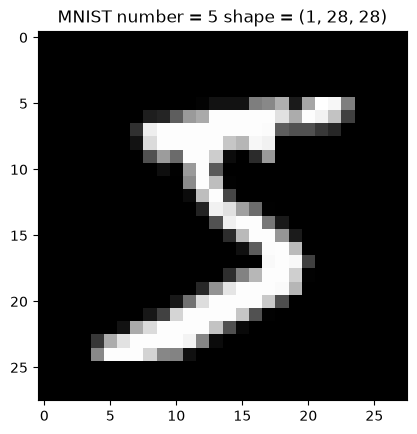

In [3]:
# Showing MNIST dataset
image, target = dataset[0]
input_size_flatten = image.numel()
classes_size = len(dataset.classes)
plt.title(f"MNIST number = {target} shape = {tuple(image.shape)}")
plt.imshow(image.squeeze().numpy(), cmap='gray')

In [4]:
print(torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

True
Using device: cuda


## Dataset Preparation
Nessa seção iremos realizar a preparação do dataset em treinamento e validação

In [5]:
train_share = 0.7
val_share = 0.15
test_share = 0.15

train_dataset, val_dataset, test_dataset = random_split(dataset, 
                                                        [train_share, val_share, test_share],
                                                        generator=torch.Generator().manual_seed(31))

batch_size = 1024 if device.type == "cuda" else 32
pin_memory = device.type == "cuda"
num_workers = 4 if device.type == "cuda" else 0

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, pin_memory=pin_memory,
                        num_workers=num_workers, persistent_workers=num_workers > 0)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_memory,
                        num_workers=num_workers, persistent_workers=num_workers > 0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_memory,
                        num_workers=num_workers, persistent_workers=num_workers > 0)

print(f"Train size: {len(train_dataset)}, Validation size: {len(val_dataset)}, Test size: {len(test_dataset)}")
print(f"Batch size: {batch_size}, Pin memory: {pin_memory}, Num workers: {num_workers}")


Train size: 42000, Validation size: 9000, Test size: 9000
Batch size: 1024, Pin memory: True, Num workers: 4


In [6]:
def GradientDescent(train_loader, val_loader, model, criteria, optimizer, epochs = 100) -> tuple:
	train_history = []
	val_history = []
	for epoch in range(epochs):
		model.train()
		running_loss = torch.zeros(1, device=device)
		for X, Y in train_loader:
			X = X.to(device, non_blocking=True)
			Y = Y.to(device, non_blocking=True)

			# Forwards pass
			prediction = model(X)
			loss = criteria(prediction, Y)

			# Backward pass
			optimizer.zero_grad(set_to_none=True)
			loss.backward()
			optimizer.step()
			
			running_loss += loss.detach() * X.size(0)
		epoch_loss = running_loss.item() / len(train_loader.dataset)
		train_history.append(epoch_loss)

		model.eval()
		running_val_loss = torch.zeros(1, device=device)
		with torch.no_grad():
			for X, Y in val_loader:
				X = X.to(device, non_blocking=True)
				Y = Y.to(device, non_blocking=True)

				output = model(X)
				loss = criteria(output, Y)
				running_val_loss += loss.detach() * X.size(0)
			epoch_val_loss = running_val_loss.item() / len(val_loader.dataset)
			val_history.append(epoch_val_loss)

	return train_history, val_history


In [7]:
def PlotLoss(history, val_history, model):
	plt.plot(range(1, len(history) + 1), history, label="Train Loss")
	plt.plot(range(1, len(val_history) + 1), val_history, label="Validation Loss")
	trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
	plt.xlabel("Epoch")
	plt.ylabel("Loss")
	plt.title(f"Training and Validation Loss. Number of params = {trainable_params}")
	plt.legend()
	plt.show()

    

In [8]:
def Evaluate(test_loader, classes_size, model):
	accuracy_metric = torchmetrics.Accuracy(task='multiclass', num_classes=classes_size).to(device)
	f1_metric = torchmetrics.F1Score(task='multiclass', num_classes=classes_size).to(device)
	confusion_matrix = torchmetrics.ConfusionMatrix(task='multiclass', num_classes=classes_size).to(device)
	precision = torchmetrics.Precision(task='multiclass', num_classes=classes_size).to(device)
	recall = torchmetrics.Recall(task='multiclass', num_classes=classes_size).to(device)
	specificity = torchmetrics.Specificity(task='multiclass', num_classes=classes_size).to(device)
	auc_roc = torchmetrics.AUROC(task='multiclass', num_classes=classes_size).to(device)
    
	model.eval()
	with torch.no_grad():
		for X, Y in test_loader:
			X = X.to(device, non_blocking=True)
			Y = Y.to(device, non_blocking=True)

			output = model(X)
			probs = torch.softmax(output, dim=1)
			pred = torch.argmax(output, dim=1)
			accuracy_metric.update(pred, Y)
			f1_metric.update(pred, Y)
			confusion_matrix.update(pred, Y)
			precision.update(pred, Y)
			recall.update(pred, Y)
			specificity.update(pred, Y)
			auc_roc.update(probs, Y)

	return accuracy_metric, \
		f1_metric, \
		confusion_matrix, \
		precision, \
		recall, \
		specificity, \
		auc_roc, \
    

In [9]:
def PrintPlotMetrics(test_loader, class_size, model):
	accuracy, f1, confusion, precision, recall, specificity, auc = Evaluate(test_loader, classes_size, model)
	print(f"Accuracy: {accuracy.compute()}")
	print(f"F1: {f1.compute()}")
	print(f"Confusion: {confusion.compute()}")
	print(f"Precision: {precision.compute()}")
	print(f"Recall: {recall.compute()}")
	print(f"Specificity: {specificity.compute()}")
	print(f"AUC: {auc.compute()}")

	confusion.plot()
	plt.show()

## Definindo rede neural
Nesta seção estamos criando uma rede neural

In [10]:
class NeuralNetwork(nn.Module):
	def __init__(self, inputSize, classes_size) -> None:
		super(NeuralNetwork, self).__init__()
		self.network = nn.Sequential(
			nn.Linear(inputSize, 256),
			nn.ReLU(), # Activation
			nn.Linear(256, 64),
			nn.ReLU(), # Activation
			nn.Linear(64, classes_size),
			# CrossEntropyLoss already applies log_softmax internally, so no Softmax here
		)
		# TODO: add dropout

	def forward(self, x):
		x = torch.flatten(x, start_dim=1)
		return self.network(x)


In [11]:
class ConvolutionNeuralNetwork(nn.Module):
	def __init__(self, inputSize, classes_size) -> None:
		super(ConvolutionNeuralNetwork, self).__init__()
		self.backbone = nn.Sequential(
			nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=1, padding=1),
			nn.ReLU(),
			nn.MaxPool2d(kernel_size=2, stride=2),
			nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
			nn.ReLU(),
			nn.MaxPool2d(kernel_size=2, stride=2)
			# CrossEntropyLoss already applies log_softmax internally, so no Softmax here
		)
		head_input_size = int(32 * inputSize * (0.5 ** 4))
		self.head = nn.Sequential(
			nn.Flatten(),
			nn.Linear(head_input_size, 128),
			nn.ReLU(),
			nn.Linear(128, classes_size)
		)
		

	def forward(self, x):
		x = self.backbone(x)
		x = self.head(x)
		return x


In [12]:
model = NeuralNetwork(input_size_flatten, classes_size).to(device)
learning_rate = 0.001
criteria = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [13]:
history, val_history = GradientDescent(train_loader, val_loader, model, criteria, optimizer, epochs=100)

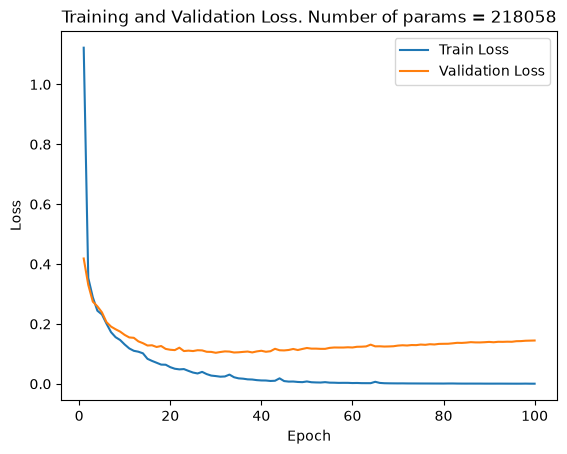

In [14]:
PlotLoss(history, val_history, model)

Accuracy: 0.976111114025116
F1: 0.976111114025116
Confusion: tensor([[ 891,    0,    2,    3,    1,    4,    1,    2,    2,    1],
        [   0, 1003,    4,    0,    1,    0,    1,    3,    0,    0],
        [   0,    2,  890,    3,    1,    0,    1,    5,    6,    0],
        [   0,    0,    7,  921,    0,   10,    0,    4,   10,    5],
        [   0,    1,    3,    0,  851,    0,    5,    2,    0,   10],
        [   1,    0,    1,    6,    0,  803,    3,    2,    4,   10],
        [   3,    1,    1,    0,    2,    0,  879,    0,    2,    0],
        [   0,    1,    3,    2,    5,    1,    0,  854,    1,    9],
        [   2,    4,    4,    6,    0,    7,    0,    3,  821,    5],
        [   2,    0,    1,    3,    7,    3,    0,    5,    5,  872]],
       device='cuda:0')
Precision: 0.976111114025116
Recall: 0.976111114025116
Specificity: 0.9973456859588623
AUC: 0.9993584752082825


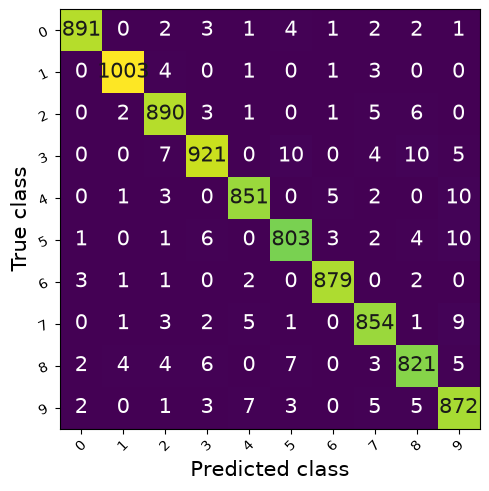

In [15]:
PrintPlotMetrics(test_loader, classes_size, model)

In [16]:
modelCNN = ConvolutionNeuralNetwork(input_size_flatten, classes_size).to(device)
learning_rate = 0.001
criteria = nn.CrossEntropyLoss()
optimizer = optim.Adam(modelCNN.parameters(), lr=learning_rate)

In [17]:
historyCNN, val_historyCNN = GradientDescent(train_loader, val_loader, modelCNN, criteria, optimizer, epochs=100)

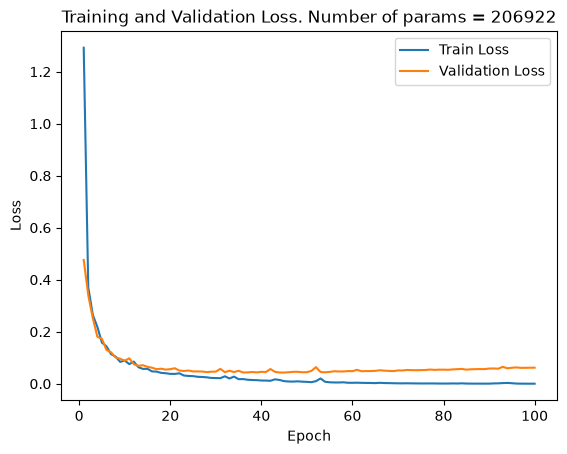

In [18]:
PlotLoss(historyCNN, val_historyCNN, modelCNN)

Accuracy: 0.9900000095367432
F1: 0.9900000095367432
Confusion: tensor([[ 898,    0,    1,    1,    0,    1,    2,    1,    2,    1],
        [   0, 1002,    3,    0,    2,    0,    1,    4,    0,    0],
        [   0,    1,  898,    0,    0,    0,    1,    5,    2,    1],
        [   0,    0,    1,  948,    0,    3,    0,    3,    0,    2],
        [   0,    0,    0,    0,  869,    0,    1,    0,    0,    2],
        [   0,    0,    1,    1,    0,  824,    0,    0,    4,    0],
        [   1,    1,    0,    0,    0,    2,  882,    0,    2,    0],
        [   0,    1,    3,    1,    2,    0,    0,  865,    0,    4],
        [   1,    1,    3,    1,    1,    3,    0,    0,  840,    2],
        [   2,    0,    0,    0,    5,    1,    0,    1,    5,  884]],
       device='cuda:0')
Precision: 0.9900000095367432
Recall: 0.9900000095367432
Specificity: 0.9988889098167419
AUC: 0.9998825192451477


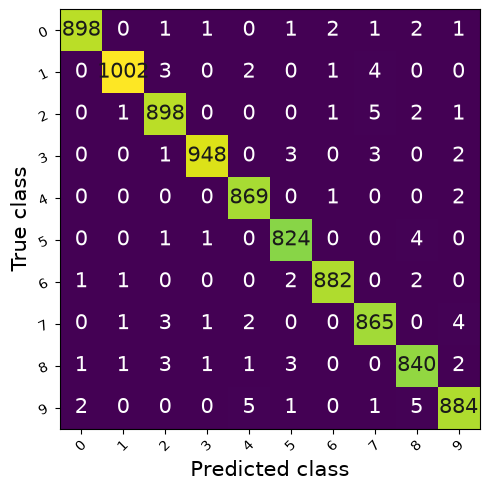

In [19]:
PrintPlotMetrics(test_loader, classes_size, modelCNN)

## Exploração adicional
Aqui iremos realizar as explorações adicionais

#### Utilizando dataset CIFAR 10

In [19]:
# Downloading MNIST
datasetCIFAR = tCIFAR.CIFAR10(
    "./data",
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

(50000, 32, 32, 3)


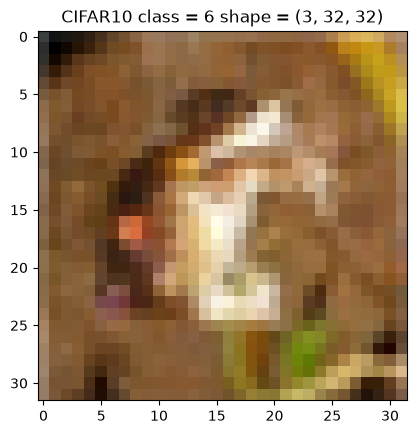

In [20]:
# Showing MNIST dataset
image, target = datasetCIFAR[0]

print(datasetCIFAR.data.shape)
input_size_flatten = image.numel()
classes_size = len(datasetCIFAR.classes)
plt.title(f"CIFAR10 class = {target} shape = {tuple(image.shape)}")
plt.imshow(image.squeeze().numpy().T, cmap='gray')

In [ ]:
gray_scale_weights = [0.2989, 0.5870, 0.1140]
gray_images = np.dot(datasetCIFAR.data, gray_scale_weights).astype(np.uint8)
datasetCIFAR.data = gray_images

image, _ = datasetCIFAR[0]
input_size_flatten = image.numel()

print(datasetCIFAR.data.shape)
print(f"Model input shape: {tuple(image.shape)}, flattened size: {input_size_flatten}")

(50000, 32, 32)


In [15]:
train_share = 0.7
val_share = 0.15
test_share = 0.15

train_dataset, val_dataset, test_dataset = random_split(datasetCIFAR, 
                                                        [train_share, val_share, test_share],
                                                        generator=torch.Generator().manual_seed(31))

batch_size = 1024 if device.type == "cuda" else 32
pin_memory = device.type == "cuda"
num_workers = 4 if device.type == "cuda" else 0

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, pin_memory=pin_memory,
                        num_workers=num_workers, persistent_workers=num_workers > 0)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_memory,
                        num_workers=num_workers, persistent_workers=num_workers > 0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_memory,
                        num_workers=num_workers, persistent_workers=num_workers > 0)

print(f"Train size: {len(train_dataset)}, Validation size: {len(val_dataset)}, Test size: {len(test_dataset)}")
print(f"Batch size: {batch_size}, Pin memory: {pin_memory}, Num workers: {num_workers}")


Train size: 35000, Validation size: 7500, Test size: 7500
Batch size: 1024, Pin memory: True, Num workers: 4


In [16]:
modelCIFAR = NeuralNetwork(input_size_flatten, classes_size).to(device)
learning_rate = 0.001
criteria = nn.CrossEntropyLoss()
optimizer = optim.Adam(modelCIFAR.parameters(), lr=learning_rate)

In [18]:
history, val_history = GradientDescent(train_loader, val_loader, modelCIFAR, criteria, optimizer, epochs=100)


RuntimeError: mat1 and mat2 shapes cannot be multiplied (1024x1024 and 3072x256)